# 04 - Fine-tune PhoBERT-base-v2 (`vinai/phobert-base-v2`) cho Extractive QA (UIT-ViQuAD 2.0)

## 0. Mục tiêu và cấu hình

Mục tiêu: so sánh PhoBERT-base-v2 với XLM-R base (notebook 02: dev F1 59.90 tuned, NoAns acc 56.81) và XLM-R large (notebook 03: dev F1 78.30 tuned, NoAns acc 76.73). PhoBERT chỉ được pretrain trên tiếng Việt, và BPE của nó hoạt động trên văn bản đã **tách từ** (word segmentation). Tách từ bằng VnCoreNLP đã chạy ở máy local; dữ liệu đã tách (`data/processed/seg/*.jsonl`) được upload lên Colab nên Colab không cần Java.

Fine-tune `vinai/phobert-base-v2` (lr 3e-5, batch 32, 3 epoch, `max_length` 256 = 258 position) trên split `train` đã làm sạch và tách từ (SQuAD-2.0 style, có câu hỏi không trả lời được), chọn `eval_loss` tốt nhất theo epoch, sau đó tune null threshold trên `dev`. Span dự đoán trên văn bản đã tách từ được ánh xạ ngược về context gốc để chấm điểm. Trần lý thuyết: khoảng 1.7% đáp án bắt đầu/kết thúc ở giữa một từ đã tách nên EM trên dev không thể vượt ~98.3%. Split `test` **không** được chạm tới ở notebook này.

Cấu hình bên dưới lấy từ `src.train_qa.CFG_PHOBERT`.

In [1]:
from pathlib import Path
import sys

# Colab: src/ and split_ids.json are uploaded to /content; local: project root (notebook lives in notebooks/)
if Path('/content').exists():
    ROOT = Path('/content')
elif Path.cwd().name == 'notebooks':
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.train_qa import CFG_PHOBERT as _CFG

# lr 3e-5 diverged in the first run (grad_norm spike 532 at step ~1850, loss 1.16 -> 2.2, F1 59.5), so lr is lowered
CFG = dict(_CFG, lr=2e-5, out_dir=str(ROOT / 'outputs' / 'phobert_base'))
pd.DataFrame({'value': CFG}).astype(str)

| value                                                                         
---|---                                                                         
model_name | vinai/phobert-base-v2                                              
max_length | 256                                                                
doc_stride | 128                                                                
lr | 2e-05                                                                      
epochs | 3                                                                      
train_bs | 32                                                                   
eval_bs | 64                                                                    
grad_accum | 1                                                                  
warmup_ratio | 0.1                                                              
weight_decay | 0.01                                                             
seed | 42                   

## 1. Môi trường

In [2]:
import platform, torch, transformers, datasets

print('python      :', platform.python_version())
print('torch       :', torch.__version__)
print('transformers:', transformers.__version__)
print('datasets    :', datasets.__version__)
print('ROOT        :', ROOT)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f'GPU         : {p.name}, {p.total_memory / 1e9:.1f} GB, bf16 supported = {torch.cuda.is_bf16_supported()}')
else:
    print('GPU         : none (CPU only, training will be very slow)')

import src.data_clean, src.preprocess, src.postprocess, src.metrics, src.train_qa
print('src/ imports OK:', Path(src.train_qa.__file__).parent)

python      : 3.13.16
torch       : 2.14.1+cu130
transformers: 5.22.1
datasets    : 4.8.5
ROOT        : /content
GPU         : NVIDIA A100-SXM4-40GB, 42.4 GB, bf16 supported = True
src/ imports OK: /content/src


## 2. Dữ liệu

`get_seg_data` đọc `data/processed/seg/{train,dev,test}.jsonl` (local) hoặc `seg_{train,dev,test}.jsonl` đặt phẳng trong `/content` (Colab). Mỗi dòng có `context` đã tách từ (từ ghép nối bằng `_`), `orig_context` và các cột như `is_impossible`. Kỳ vọng: train 25.533 dòng (9 dòng bị loại khi tách từ so với 25.542), dev 2.912, test 3.814.

In [3]:
from src.train_qa import build_features
from src.phobert import get_seg_data
from IPython.display import Markdown, display

ds = get_seg_data(ROOT)
assert {k: len(ds[k]) for k in ds} == {'train': 25533, 'dev': 2912, 'test': 3814}, {k: len(ds[k]) for k in ds}
rows = []
for k in ('train', 'dev', 'test'):
    n_no = sum(ds[k]['is_impossible'])
    rows.append({'split': k, 'examples': len(ds[k]), 'NoAns': n_no, 'NoAns %': round(100 * n_no / len(ds[k]), 2)})
sizes = pd.DataFrame(rows).set_index('split')
display(sizes)
display(Markdown(
    f"Train có {sizes.loc['train', 'examples']:,} ví dụ với {sizes.loc['train', 'NoAns %']}% NoAns, "
    f"dev {sizes.loc['dev', 'examples']:,} ví dụ ({sizes.loc['dev', 'NoAns %']}% NoAns, tách theo title nên không rò rỉ bài viết sang train), "
    f"test {sizes.loc['test', 'examples']:,} ví dụ ({sizes.loc['test', 'NoAns %']}% NoAns)."))
for k in ('dev', 'test'):
    if 'align_error' in ds[k].column_names:
        n_err = sum(bool(x) for x in ds[k]['align_error'])
        print(f'{k}: align_error = {n_err} (kỳ vọng 0)')
        assert n_err == 0, k
print('columns:', ds['train'].column_names)


| examples | NoAns | NoAns %                                                    
---|---|---|---                                                                 
split |  |  |                                                                   
train | 25533 | 8258 | 32.34                                                    
dev | 2912 | 954 | 32.76                                                        
test | 3814 | 1161 | 30.44                                                      
Train có 25,533 ví dụ với 32.34% NoAns, dev 2,912 ví dụ (32.76% NoAns, tách theo
title nên không rò rỉ bài viết sang train), test 3,814 ví dụ (30.44% NoAns).    
columns: ['id', 'title', 'context', 'question', 'answers', 'is_impossible', 'orig_context', 'ref_texts']


## 3. Tokenize (sliding window)

Context dài hơn `max_length` được cắt thành nhiều window (`doc_stride` chồng lấp). Window không chứa đáp án được gán nhãn `[CLS]` (null).

In [4]:
from src.phobert import load_phobert_tokenizer

tok = load_phobert_tokenizer()
feats = build_features(ds, tok, CFG, CFG['max_train'], CFG['max_dev'])
train_f, dev_loss_f, dev_eval_f, dev_ex = feats
n_tr, n_dv = CFG['max_train'] or len(ds['train']), len(dev_ex)
w_tr, w_dv = len(train_f) / n_tr, len(dev_eval_f) / n_dv
display(pd.DataFrame({'examples': [n_tr, n_dv], 'windows': [len(train_f), len(dev_eval_f)],
                      'windows/example': [round(w_tr, 3), round(w_dv, 3)]}, index=['train', 'dev']))
display(Markdown(
    f"Trung bình {w_tr:.3f} window/ví dụ ở train và {w_dv:.3f} ở dev (max_length {CFG['max_length']}, doc_stride {CFG['doc_stride']}); "
    f"số window thực là {len(train_f):,} cho một epoch."))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]
Map:   0%|          | 0/2912 [00:00<?, ? examples/s]
windows: train 29128 from 25533 examples (1.141/ex), dev 3340 from 2912 examples (1.147/ex)
| examples | windows | windows/example                                          
---|---|---|---                                                                 
train | 25533 | 29128 | 1.141                                                   
dev | 2912 | 3340 | 1.147                                                       
Trung bình 1.141 window/ví dụ ở train và 1.147 ở dev (max_length 256, doc_stride
128); số window thực là 29,128 cho một ep

## 4. Huấn luyện

`run(CFG, ds=ds, feats=feats)` train với HF `Trainer` (eval/save theo epoch, `load_best_model_at_end` theo `eval_loss`), chấm dev, và lưu `model/`, `dev_threshold.json`, `train_summary.json` vào `out_dir`. Cell này chạy lâu nhất.

In [5]:
import time
from src.train_qa import run

t0 = time.time()
summary = run(CFG, ds=ds, feats=feats)
print(f'done in {(time.time() - t0) / 60:.1f} min (train_runtime {summary["train_runtime_s"]:.0f}s)')

device: {'name': 'NVIDIA A100-SXM4-40GB', 'total_memory_gb': 42.405855232}
config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]
pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB        
pytorch_model.bin: downloading bytes:           |  0.00B            
Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]
[transformers] RobertaForQuestionAnswering LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
qa_outputs.weight         | MISSING    | 
qa_outputs.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

## 5. Đường cong học

Train loss cuối 1.008 (từ 5.449). Eval loss theo epoch: 1.275, 1.118, 1.107; tốt
nhất 1.107 tại step 2733 (checkpoint này được load lại). Eval loss giảm đều,    
chưa thấy overfit.                                                              


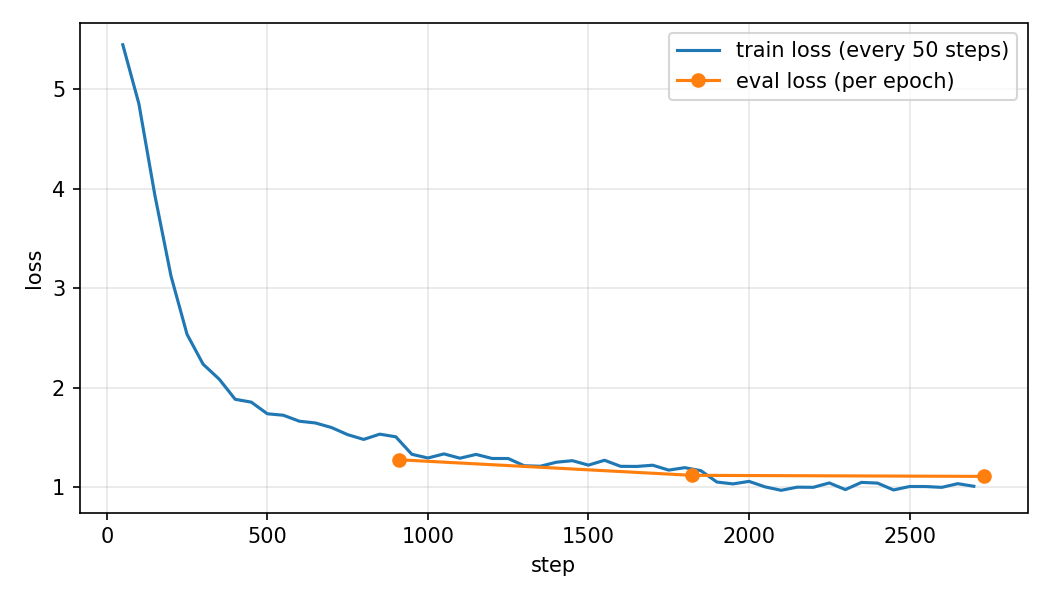

In [6]:
import matplotlib
import matplotlib.pyplot as plt

OUT = Path(CFG['out_dir'])
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
hist = summary['log_history']
tr = [(h['step'], h['loss']) for h in hist if 'loss' in h]
ev = [(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]
fig, ax = plt.subplots(figsize=(7, 4))
if tr:
    ax.plot(*zip(*tr), label='train loss (every 50 steps)')
if ev:
    ax.plot(*zip(*ev), 'o-', label='eval loss (per epoch)')
ax.set_xlabel('step'); ax.set_ylabel('loss'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'learning_curves.png', dpi=150); plt.close(fig)

best_ev = min(ev, key=lambda x: x[1]) if ev else None
txt = f"Train loss cuối {tr[-1][1]:.3f} (từ {tr[0][1]:.3f}). " if tr else "Không có train loss được log. "
if ev:
    ev_s = ', '.join(f'{v:.3f}' for _, v in ev)
    verdict = ('Eval loss tăng ở epoch cuối so với tốt nhất, dấu hiệu overfit nhẹ.' if ev[-1][1] > best_ev[1]
               else 'Eval loss giảm đều, chưa thấy overfit.')
    txt += f"Eval loss theo epoch: {ev_s}; tốt nhất {best_ev[1]:.3f} tại step {best_ev[0]} (checkpoint này được load lại). {verdict}"
display(Markdown(txt))

## 6. Đánh giá dev và chọn ngưỡng

Quyết định NoAns: trả lời rỗng khi `null_score - best_span_score > threshold`. Ngưỡng được tune trên dev bằng cách tối đa hóa F1 tổng.

| threshold 0 | tuned (-1.50)                                                   
---|---|---                                                                     
EM | 49.93 | 52.06                                                              
F1 | 66.75 | 67.52                                                              
HasAns_F1 | 75.02 | 69.41                                                       
NoAns_acc | 49.79 | 63.63                                                       
Tune ngưỡng từ 0 lên -1.50 đổi F1 dev từ 66.75 thành 67.52 (+0.77), NoAns_acc từ
49.79 thành 63.63, HasAns_F1 từ 75.02 thành 69.41.                              

Lưu ý: ngưỡng được tune ngay trên dev nên điểm dev ở cột tuned là lạc quan      
(optimistic) và không so sánh trực tiếp được với điểm test (validation gốc).    
Split test chỉ được chấm một lần, với ngưỡng cố định này, ở notebook đánh giá   
test sau này.                                                                   


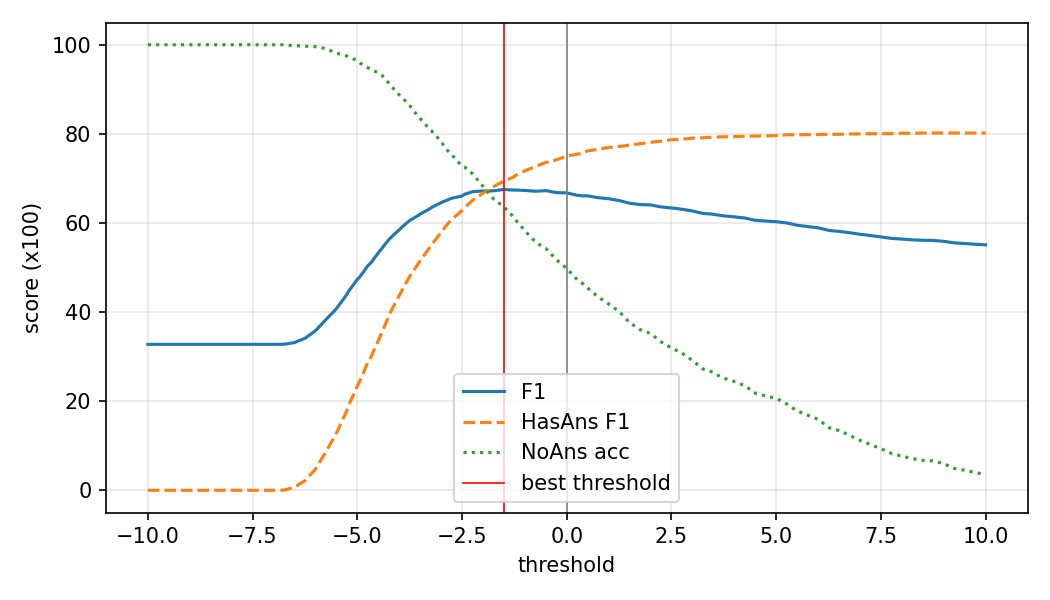

In [7]:
dev = summary['dev']
thr = pd.DataFrame(dev['table']).sort_values('threshold')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr['threshold'], thr['f1'], label='F1')
ax.plot(thr['threshold'], thr['HasAns_f1'], '--', label='HasAns F1')
ax.plot(thr['threshold'], thr['NoAns_acc'], ':', label='NoAns acc')
ax.axvline(0, color='gray', lw=.8); ax.axvline(dev['best_threshold'], color='r', lw=.8, label='best threshold')
ax.set_xlabel('threshold'); ax.set_ylabel('score (x100)'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'f1_vs_threshold.png', dpi=150); plt.close(fig)

m0, mb = dev['metrics_at_0'], dev['metrics_at_best']
cmp_ = pd.DataFrame({
    'threshold 0': [m0['exact'], m0['f1'], m0['HasAns_f1'], m0['NoAns_exact']],
    f"tuned ({dev['best_threshold']:.2f})": [mb['exact'], mb['f1'], mb['HasAns_f1'], mb['NoAns_exact']],
}, index=['EM', 'F1', 'HasAns_F1', 'NoAns_acc']).round(2)
display(cmp_)
display(Markdown(
    f"Tune ngưỡng từ 0 lên {dev['best_threshold']:.2f} đổi F1 dev từ {m0['f1']:.2f} thành {mb['f1']:.2f} "
    f"({mb['f1'] - m0['f1']:+.2f}), NoAns_acc từ {m0['NoAns_exact']:.2f} thành {mb['NoAns_exact']:.2f}, "
    f"HasAns_F1 từ {m0['HasAns_f1']:.2f} thành {mb['HasAns_f1']:.2f}.\n\n"
    "**Lưu ý:** ngưỡng được tune ngay trên dev nên điểm dev ở cột tuned là lạc quan (optimistic) và "
    "**không so sánh trực tiếp** được với điểm test (validation gốc). Split test chỉ được chấm một lần, với ngưỡng cố định này, ở notebook đánh giá test sau này."))

## 7. Tài nguyên

In [8]:
RATE_UNITS_PER_HR = 6.73  # Colab compute units per hour, A100
rt = summary['train_runtime_s']
hours = rt / 3600
gpu = summary['gpu']
res = pd.DataFrame({'value': {
    'GPU': gpu['name'],
    'train_runtime (min)': round(rt / 60, 1),
    'samples/sec (windows)': round(summary['samples_per_sec'], 1),
    'peak GPU memory (GB)': None if summary['peak_mem_gb'] is None else round(summary['peak_mem_gb'], 2),
    'est. compute units': round(hours * RATE_UNITS_PER_HR, 2),
}})
display(res.astype(str))
display(Markdown(
    f"Huấn luyện mất {rt / 60:.1f} phút ({hours:.2f} giờ) trên {gpu['name']}, "
    f"~{summary['samples_per_sec']:.1f} window/s, peak memory {summary['peak_mem_gb'] or 0:.2f} GB "
    f"trên tổng {gpu['total_memory_gb'] or 0:.1f} GB. Ước tính {hours:.2f} h x {RATE_UNITS_PER_HR} = "
    f"**{hours * RATE_UNITS_PER_HR:.2f} compute units** (chỉ đúng nếu GPU là A100; chưa tính thời gian tải data/model và chấm dev)."))

| value                                                                         
---|---                                                                         
GPU | NVIDIA A100-SXM4-40GB                                                     
train_runtime (min) | 3.0                                                       
samples/sec (windows) | 491.8                                                   
peak GPU memory (GB) | 5.22                                                     
est. compute units | 0.33                                                       
Huấn luyện mất 3.0 phút (0.05 giờ) trên NVIDIA A100-SXM4-40GB, ~491.8 window/s, 
peak memory 5.22 GB trên tổng 42.4 GB. Ước tính 0.05 h x 6.73 = 0.33 compute    
units (chỉ đúng nếu GPU là A100; chưa tính thời gian tải data/model và chấm     
dev).                                                                           


## 8. Lưu artifact

In [9]:
import tarfile

files = sorted(p for p in (OUT / 'model').rglob('*') if p.is_file())
display(pd.DataFrame({'file': [str(p.relative_to(OUT)) for p in files],
                      'MB': [round(p.stat().st_size / 1e6, 2) for p in files]}))
tar_path = OUT / 'out.tar'
with tarfile.open(tar_path, 'w') as tf:
    tf.add(OUT / 'model', arcname='model')
    for name in ('dev_threshold.json', 'train_summary.json'):
        tf.add(OUT / name, arcname=name)
print(f'{tar_path} ({tar_path.stat().st_size / 1e6:.0f} MB)')

| file | MB                                                                     
---|---|---                                                                     
0 | model/config.json | 0.00                                                    
1 | model/model.safetensors | 537.66                                            
2 | model/tokenizer.json | 4.99                                                 
3 | model/tokenizer_config.json | 0.00                                          
/content/outputs/phobert_base/out.tar (543 MB)


## Tải artifact về máy

Toàn bộ kết quả nằm trong một file `out.tar` (gồm `model/`, `dev_threshold.json`, `train_summary.json`). Tải về bằng Colab CLI (`colab download` đường dẫn `/content/outputs/phobert_base/out.tar`) hoặc panel Files của Colab, rồi giải nén vào `outputs/phobert_base/` trong project: `tar -xf out.tar -C outputs/phobert_base`. Notebook đánh giá test sẽ đọc `model/` và `dev_threshold.json` từ đó.

In [10]:
base = pd.DataFrame({
    'base thr0': [45.71, 59.58, 68.63, 40.99],
    'base tuned(-1.0)': [47.84, 59.90, 61.41, 56.81],
}, index=['EM', 'F1', 'HasAns_F1', 'NoAns_acc'])
large = pd.DataFrame({
    'large thr0': [62.47, 78.12, 79.88, 74.53],
    'large tuned(-0.63)': [62.84, 78.30, 79.06, 76.73],
}, index=base.index)
d = summary['dev']; a0, ab = d['metrics_at_0'], d['metrics_at_best']
pho = pd.DataFrame({
    'phobert thr0': [a0['exact'], a0['f1'], a0['HasAns_f1'], a0['NoAns_exact']],
    f"phobert tuned({d['best_threshold']:.2f})": [ab['exact'], ab['f1'], ab['HasAns_f1'], ab['NoAns_exact']],
}, index=base.index)
display(pd.concat([base, large, pho], axis=1).round(2))
print(f"Tuned: phobert F1 {ab['f1']:.2f} vs base 59.90 ({ab['f1'] - 59.90:+.2f}), vs large 78.30 ({ab['f1'] - 78.30:+.2f}); "
      f"NoAns_acc {ab['NoAns_exact']:.2f} vs base 56.81 ({ab['NoAns_exact'] - 56.81:+.2f}), vs large 76.73 ({ab['NoAns_exact'] - 76.73:+.2f}); "
      f"HasAns_F1 {ab['HasAns_f1']:.2f} vs base 61.41 ({ab['HasAns_f1'] - 61.41:+.2f}), vs large 79.06 ({ab['HasAns_f1'] - 79.06:+.2f}).")


| base thr0 | base tuned(-1.0) | large thr0 | large tuned(-0.63) | phobert thr0 
| phobert tuned(-1.50)                                                          
---|---|---|---|---|---|---                                                     
EM | 45.71 | 47.84 | 62.47 | 62.84 | 49.93 | 52.06                              
F1 | 59.58 | 59.90 | 78.12 | 78.30 | 66.75 | 67.52                              
HasAns_F1 | 68.63 | 61.41 | 79.88 | 79.06 | 75.02 | 69.41                       
NoAns_acc | 40.99 | 56.81 | 74.53 | 76.73 | 49.79 | 63.63                       
Tuned: phobert F1 67.52 vs base 59.90 (+7.62), vs large 78.30 (-10.78); NoAns_acc 63.63 vs base 56.81 (+6.82), vs large 76.73 (-13.10); HasAns_F1 69.41 vs base 61.41 (+8.00), vs large 79.06 (-9.65).
